In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, classification_report, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("D:/Mrunmayee/OneDrive/Desktop/student-performance-project/data/processed/student_encoded.csv")
df['pass_fail'] = (df['G3'] >= 10).astype(int)
print(df['pass_fail'].value_counts())

pass_fail
1    265
0    130
Name: count, dtype: int64


Build Model A and Model B 

In [2]:
# ---------- MODEL A: Classification WITH G1/G2 ----------
X_a = df.drop(columns=['G3', 'pass_fail'])
y = df['pass_fail']

X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_a, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train size: {X_train_a.shape[0]}, Test size: {X_test_a.shape[0]}")

Train size: 316, Test size: 79


# Logistic Regression - Model A

In [3]:
log_reg_a = LogisticRegression(max_iter=1000)
log_reg_a.fit(X_train_a, y_train_a)
pred_logreg_a = log_reg_a.predict(X_test_a)

print("--- Model A: Logistic Regression (WITH G1/G2) ---")
print(classification_report(y_test_a, pred_logreg_a))

cm_a = confusion_matrix(y_test_a, pred_logreg_a)
print("Confusion Matrix:\n", cm_a)

--- Model A: Logistic Regression (WITH G1/G2) ---
              precision    recall  f1-score   support

           0       0.77      0.92      0.84        26
           1       0.96      0.87      0.91        53

    accuracy                           0.89        79
   macro avg       0.87      0.90      0.88        79
weighted avg       0.90      0.89      0.89        79

Confusion Matrix:
 [[24  2]
 [ 7 46]]


# Decision Tree Classifier - Model A

In [4]:
dt_a = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_a.fit(X_train_a, y_train_a)
pred_dt_a = dt_a.predict(X_test_a)

print("\n--- Model A: Decision Tree (WITH G1/G2) ---")
print(classification_report(y_test_a, pred_dt_a))


--- Model A: Decision Tree (WITH G1/G2) ---
              precision    recall  f1-score   support

           0       0.71      0.96      0.82        26
           1       0.98      0.81      0.89        53

    accuracy                           0.86        79
   macro avg       0.85      0.89      0.85        79
weighted avg       0.89      0.86      0.86        79



Model - B

In [5]:
# ---------- MODEL B: Classification WITHOUT G1/G2 ----------
X_b = df.drop(columns=['G1', 'G2', 'G3', 'pass_fail'])

X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_b, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train size: {X_train_b.shape[0]}, Test size: {X_test_b.shape[0]}")

Train size: 316, Test size: 79


# Logistic Regression - Model B

In [6]:
log_reg_b = LogisticRegression(max_iter=1000)
log_reg_b.fit(X_train_b, y_train_b)
pred_logreg_b = log_reg_b.predict(X_test_b)

print("--- Model B: Logistic Regression (WITHOUT G1/G2) ---")
print(classification_report(y_test_b, pred_logreg_b))

--- Model B: Logistic Regression (WITHOUT G1/G2) ---
              precision    recall  f1-score   support

           0       0.47      0.35      0.40        26
           1       0.72      0.81      0.76        53

    accuracy                           0.66        79
   macro avg       0.60      0.58      0.58        79
weighted avg       0.64      0.66      0.64        79



# Decision Tree Classifier - Model B

In [7]:
dt_b = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_b.fit(X_train_b, y_train_b)
pred_dt_b = dt_b.predict(X_test_b)

print("\n--- Model B: Decision Tree (WITHOUT G1/G2) ---")
print(classification_report(y_test_b, pred_dt_b))


--- Model B: Decision Tree (WITHOUT G1/G2) ---
              precision    recall  f1-score   support

           0       0.50      0.35      0.41        26
           1       0.72      0.83      0.77        53

    accuracy                           0.67        79
   macro avg       0.61      0.59      0.59        79
weighted avg       0.65      0.67      0.65        79



# Confusion matrix heatmap

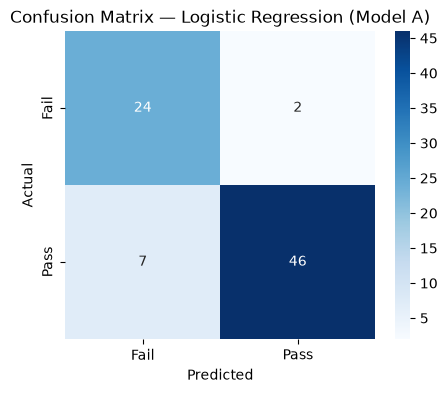

In [8]:
plt.figure(figsize=(5,4))
sns.heatmap(cm_a, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Fail','Pass'], yticklabels=['Fail','Pass'])
plt.title("Confusion Matrix — Logistic Regression (Model A)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.savefig("D:/Mrunmayee/OneDrive/Desktop/student-performance-project/outputs/figures/confusion_matrix_logreg_a.png")
plt.show()

Accuracy comparison table

In [9]:
comparison_clf = pd.DataFrame({
    'Model': ['Logistic Reg (with G1/G2)', 'Logistic Reg (without G1/G2)',
              'Decision Tree (with G1/G2)', 'Decision Tree (without G1/G2)'],
    'Accuracy': [
        accuracy_score(y_test_a, pred_logreg_a),
        accuracy_score(y_test_b, pred_logreg_b),
        accuracy_score(y_test_a, pred_dt_a),
        accuracy_score(y_test_b, pred_dt_b)
    ],
    'F1_Score': [
        f1_score(y_test_a, pred_logreg_a),
        f1_score(y_test_b, pred_logreg_b),
        f1_score(y_test_a, pred_dt_a),
        f1_score(y_test_b, pred_dt_b)
    ]
})
print(comparison_clf)
comparison_clf.to_csv("D:/Mrunmayee/OneDrive/Desktop/student-performance-project/outputs/tables/classification_comparison.csv", index=False)

                           Model  Accuracy  F1_Score
0      Logistic Reg (with G1/G2)  0.886076  0.910891
1   Logistic Reg (without G1/G2)  0.658228  0.761062
2     Decision Tree (with G1/G2)  0.860759  0.886598
3  Decision Tree (without G1/G2)  0.670886  0.771930


In [10]:
import pickle

# Save the Decision Tree classifier from Model B (the realistic, no-leakage version)
pickle.dump(dt_b, open("D:/Mrunmayee/OneDrive/Desktop/student-performance-project/dashboard/model_classifier.pkl", "wb"))
print("Classifier model saved for dashboard use.")

Classifier model saved for dashboard use.


In [11]:
print("Always-Pass baseline accuracy:", round(y_test_b.mean(), 3))
print("Model B Decision Tree confusion matrix:\n", confusion_matrix(y_test_b, pred_dt_b))

Always-Pass baseline accuracy: 0.671
Model B Decision Tree confusion matrix:
 [[ 9 17]
 [ 9 44]]
